# Semana 3 — Aprendizaje No Supervisado
Dataset: Olist Brazilian E-commerce | Modelos: K-Means segmentación de clientes · Elección de K (codo + Silhouette) · Exportación Power BI

## Importamos librerías, pandas para trabajar en dataframes, seabron y matplotlib para graficar

In [1]:
import pandas as pd #importamos pandas para el manejo de dataframes (tablas)
import seaborn as sns #importamos seaborn para graficas avanzadas
import matplotlib.pyplot as plt #importamos matplotlib para gráficas 
import matplotlib.gridspec as gridspec #importamos matplotlib para gráficas 
from scipy import stats #importamos scipy para cálculo stadístico
import matplotlib.ticker as mticker 
import numpy as np #importamos numpy para manipular arreglos. 

In [2]:
#Carga de archivos dataset a utilizar, se basará en análisis 
orders = pd.read_csv('olist_orders_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')

In [3]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


## Procesamiento de las bases de datos. 

Previo a generar el modelado de la base de datos en Python, vamos a proceder a revisar cada uno de los dataset, procesar y limpiar conforme sea necesario

In [4]:
# 2. INSPECCIÓN INDIVIDUAL
# ─────────────────────────────────────────────
datasets = {
    'orders': orders, 'items': items, 'customers': customers,
    'reviews': reviews, 'payments': payments,
    'products': products, 'sellers': sellers
}

for nombre, df in datasets.items():
    print(f"\n{'='*50}")
    print(f"  {nombre.upper()}  →  {df.shape[0]:,} filas | {df.shape[1]} columnas")
    print(f"{'='*50}")
    print(df.dtypes.to_string())
    print(f"\nNulos:\n{df.isnull().sum()[df.isnull().sum() > 0].to_string()}")
    print(f"\nMuestra:\n{df.head(2).to_string()}")


  ORDERS  →  99,441 filas | 8 columnas
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str

Nulos:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

Muestra:
                           order_id                       customer_id order_status order_purchase_timestamp    order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15          2017-10-04 19:55:00           2017-10-10 21:25:13           2017-10-18 00:00:00
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef    delivered      2018-07-

In [5]:
orders
print("=" * 60)
print("1. DIMENSIONES Y TIPOS DE DATOS")
print("=" * 60)
print(f"Filas: {orders.shape[0]:,}  |  Columnas: {orders.shape[1]}")
print(f"\nTipos de datos:\n{orders.dtypes}")

1. DIMENSIONES Y TIPOS DE DATOS
Filas: 99,441  |  Columnas: 8

Tipos de datos:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object



2. DISTRIBUCIÓN DE order_status
              cantidad  porcentaje
order_status                      
delivered        96478       97.02
shipped           1107        1.11
canceled           625        0.63
unavailable        609        0.61
invoiced           314        0.32
processing         301        0.30
created              5        0.01
approved             2        0.00


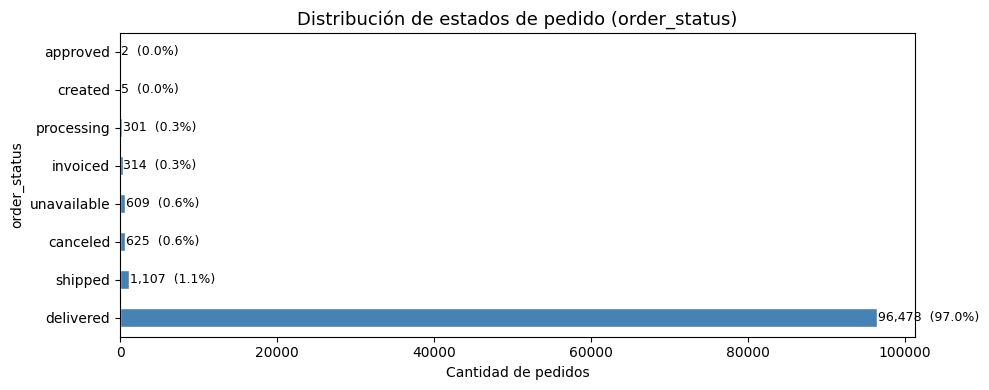


INTERPRETACIÓN:
- 'delivered' domina con ~97% → dataset muy sesgado hacia pedidos completados.
- Los estados 'shipped', 'canceled', 'unavailable' son minoritarios.
- Para modelos predictivos, si usamos order_status como target necesitaremos
  técnicas de balanceo (SMOTE, class_weight) dado el desbalance.



In [6]:
#ESTADÍSTICOS DESCRIPTIVOS BÁSICOS
#    (antes de convertir fechas, para ver qué tenemos crudo)
# ─────────────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("2. DISTRIBUCIÓN DE order_status")
print("=" * 60)
status_counts = orders['order_status'].value_counts()
status_pct    = orders['order_status'].value_counts(normalize=True) * 100

resumen_status = pd.DataFrame({
    'cantidad': status_counts,
    'porcentaje': status_pct.round(2)
})
print(resumen_status)

# Visualización
fig, ax = plt.subplots(figsize=(10, 4))
status_counts.plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Distribución de estados de pedido (order_status)', fontsize=13)
ax.set_xlabel('Cantidad de pedidos')
for i, v in enumerate(status_counts):
    ax.text(v + 100, i, f'{v:,}  ({v/len(orders)*100:.1f}%)', va='center', fontsize=9)
plt.tight_layout()
plt.show()

# INTERPRETACIÓN PEDAGÓGICA
print("""
INTERPRETACIÓN:
- 'delivered' domina con ~97% → dataset muy sesgado hacia pedidos completados.
- Los estados 'shipped', 'canceled', 'unavailable' son minoritarios.
- Para modelos predictivos, si usamos order_status como target necesitaremos
  técnicas de balanceo (SMOTE, class_weight) dado el desbalance.
""")

3. MAPA DE NULOS
                               nulos  porcentaje
order_delivered_customer_date   2965        2.98
order_delivered_carrier_date    1783        1.79
order_approved_at                160        0.16


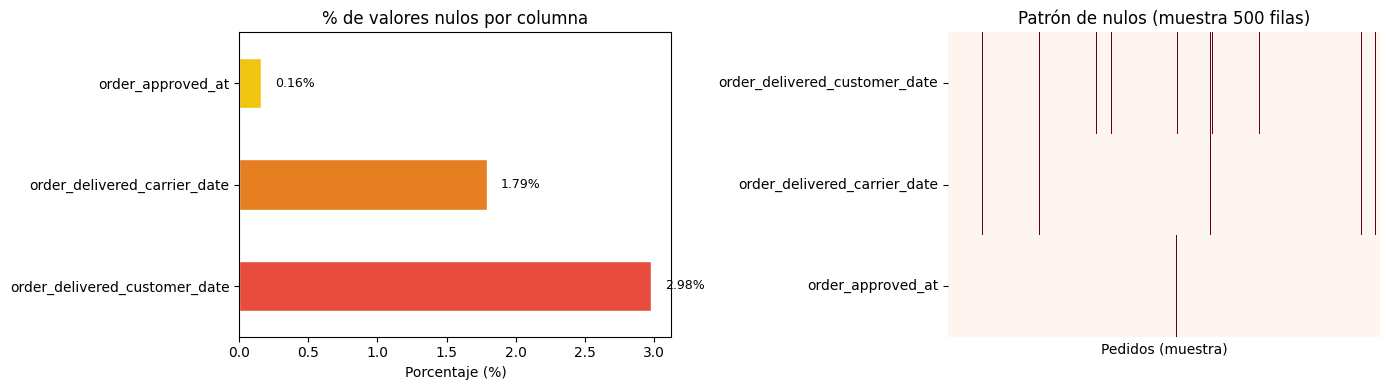

In [7]:
print("=" * 60)
print("3. MAPA DE NULOS")
print("=" * 60)

nulos = pd.DataFrame({
    'nulos':      orders.isnull().sum(),
    'porcentaje': (orders.isnull().sum() / len(orders) * 100).round(2)
})
nulos = nulos[nulos['nulos'] > 0].sort_values('nulos', ascending=False)
print(nulos)

# Visualización mapa de nulos
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Barras de % nulos
nulos['porcentaje'].plot(kind='barh', ax=axes[0],
                         color=['#e74c3c','#e67e22','#f1c40f'],
                         edgecolor='white')
axes[0].set_title('% de valores nulos por columna', fontsize=12)
axes[0].set_xlabel('Porcentaje (%)')
for i, v in enumerate(nulos['porcentaje']):
    axes[0].text(v + 0.1, i, f'{v}%', va='center', fontsize=9)

# Heatmap de nulos (muestra de 500 filas para visualizar el patrón)
muestra_nulos = orders[nulos.index].isnull().astype(int).sample(500, random_state=42)
sns.heatmap(muestra_nulos.T, cmap='Reds', cbar=False,
            yticklabels=True, xticklabels=False, ax=axes[1])
axes[1].set_title('Patrón de nulos (muestra 500 filas)', fontsize=12)
axes[1].set_xlabel('Pedidos (muestra)')

plt.tight_layout()
plt.show()

In [8]:
print("=" * 60)
print("4. NULOS SEGÚN order_status (nulos con lógica de negocio)")
print("=" * 60)

cols_fecha = [
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]

for col in cols_fecha:
    print(f"\n--- {col} ---")
    tabla = orders.groupby('order_status')[col].apply(
        lambda x: x.isnull().sum()
    ).reset_index()
    tabla.columns = ['order_status', 'nulos']
    tabla['total_status'] = tabla['order_status'].map(
        orders['order_status'].value_counts()
    )
    tabla['pct_nulo'] = (tabla['nulos'] / tabla['total_status'] * 100).round(1)
    tabla = tabla[tabla['nulos'] > 0].sort_values('nulos', ascending=False)
    print(tabla.to_string(index=False))

print("""
CONCLUSIÓN PEDAGÓGICA — nulos con lógica de negocio:
┌─────────────────────────────────────────────────────────────┐
│ order_approved_at      → nulo si pedido fue cancelado       │
│                          antes de aprobarse (160 casos)     │
│                                                             │
│ order_delivered_       → nulo si el pedido aún no salió     │
│ carrier_date             al transportista (shipped, etc.)   │
│                                                             │
│ order_delivered_       → nulo si el cliente AÚN no recibió  │
│ customer_date            (shipped, processing, canceled)    │
└─────────────────────────────────────────────────────────────┘
DECISIÓN: NO imputar con media/mediana. Son MCAR* estructurales.
(*Missing Completely At Random por diseño del proceso)
""")

4. NULOS SEGÚN order_status (nulos con lógica de negocio)

--- order_approved_at ---
order_status  nulos  total_status  pct_nulo
    canceled    141           625      22.6
   delivered     14         96478       0.0
     created      5             5     100.0

--- order_delivered_carrier_date ---
order_status  nulos  total_status  pct_nulo
 unavailable    609           609     100.0
    canceled    550           625      88.0
    invoiced    314           314     100.0
  processing    301           301     100.0
     created      5             5     100.0
    approved      2             2     100.0
   delivered      2         96478       0.0

--- order_delivered_customer_date ---
order_status  nulos  total_status  pct_nulo
     shipped   1107          1107     100.0
    canceled    619           625      99.0
 unavailable    609           609     100.0
    invoiced    314           314     100.0
  processing    301           301     100.0
   delivered      8         96478       0.0
  

In [9]:
# ─────────────────────────────────────────────
# CONVERSIÓN DE FECHAS  (orders)
# ─────────────────────────────────────────────
date_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

# ─────────────────────────────────────────────
# 4. AGREGACIONES PREVIAS AL JOIN
#    (evita duplicar filas en el merge)
# ─────────────────────────────────────────────

# items → un registro por order_id
# Si un pedido tiene 3 ítems los consolida en una fila
items_agg = items.groupby('order_id').agg(
    n_items            = ('order_item_id', 'count'),
    precio_total_items = ('price', 'sum'),
    flete_total        = ('freight_value', 'sum'),
    precio_unitario_max= ('price', 'max'),
    precio_unitario_min= ('price', 'min'),
    # seller más frecuente del pedido (modo)
    seller_id_principal= ('seller_id', lambda x: x.mode()[0]),
    product_id_principal=('product_id', lambda x: x.mode()[0]),
    shipping_limit_date= ('shipping_limit_date', 'max')
).reset_index()

# payments → un registro por order_id
payments_agg = payments.groupby('order_id').agg(
    payment_value_total  = ('payment_value', 'sum'),
    payment_installments = ('payment_installments', 'max'),
    payment_type         = ('payment_type', lambda x: x.mode()[0]),
    n_payment_methods    = ('payment_type', 'nunique')
).reset_index()

# reviews → un registro por order_id (tomar la más reciente si hay varias)
reviews_last = (
    reviews
    .sort_values('review_answer_timestamp')
    .groupby('order_id')
    .last()
    .reset_index()
    [['order_id', 'review_score', 'review_creation_date', 'review_answer_timestamp']]
)

# Construcción del modelo, creación de una sábana de datos completa para procesamiento con ML. 

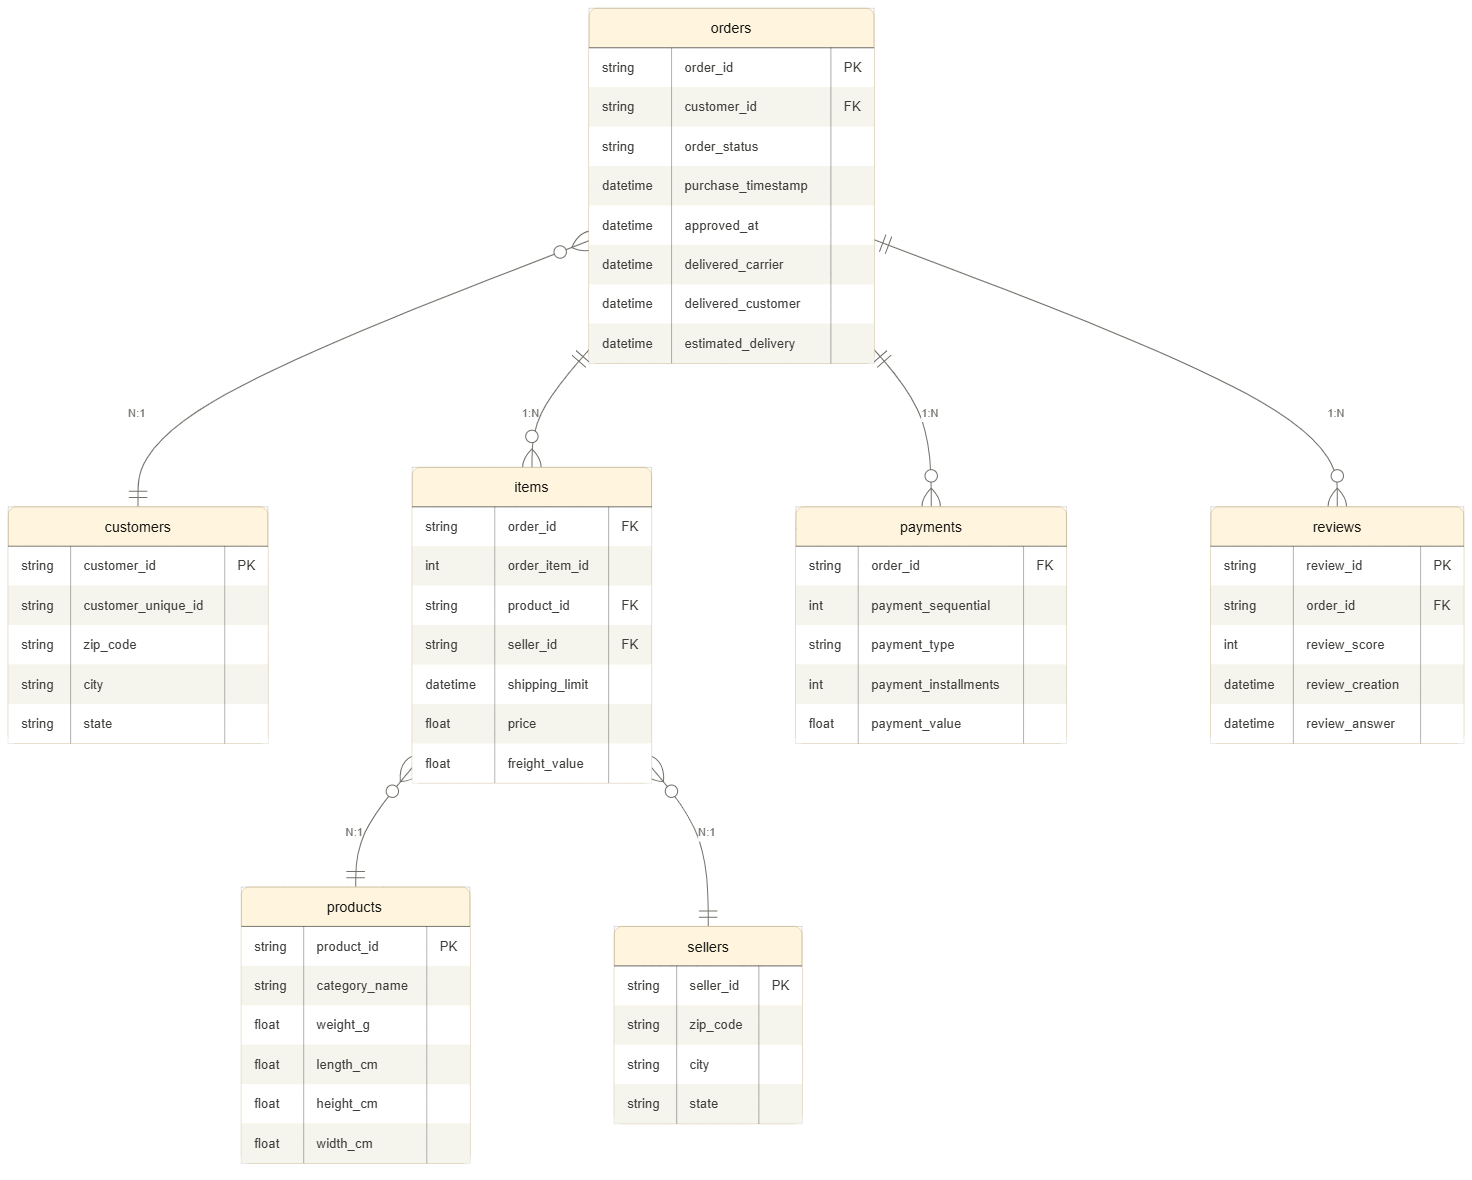

In [10]:
# ─────────────────────────────────────────────
# 5. CONSTRUCCIÓN DE LA SÁBANA  (LEFT JOINs)
#    Tabla base: orders (99.441 pedidos)
# ─────────────────────────────────────────────

sabana = (
    orders
    # → customers (info del comprador)
    .merge(customers, on='customer_id', how='left')

    # → items agregados (precios, cantidad de ítems)
    .merge(items_agg, on='order_id', how='left')

    # → payments agregados (valor pagado, cuotas, método)
    .merge(payments_agg, on='order_id', how='left')

    # → reviews (score)
    .merge(reviews_last, on='order_id', how='left')

    # → products (del ítem principal del pedido)
    .merge(
        products[['product_id', 'product_category_name',
                  'product_weight_g', 'product_length_cm',
                  'product_height_cm', 'product_width_cm']],
        left_on='product_id_principal',
        right_on='product_id',
        how='left'
    )

    # → sellers (del seller principal del pedido)
    .merge(
        sellers[['seller_id', 'seller_city', 'seller_state']],
        left_on='seller_id_principal',
        right_on='seller_id',
        how='left'
    )
)

print(f"\nSábana construida: {sabana.shape[0]:,} filas × {sabana.shape[1]} columnas")


Sábana construida: 99,441 filas × 36 columnas


In [11]:
sabana.describe()

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_zip_code_prefix,n_items,precio_total_items,flete_total,precio_unitario_max,precio_unitario_min,payment_value_total,payment_installments,n_payment_methods,review_score,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,99441,99281,97658,96476,99441,99441.000000,98666.000000,98666.000000,98666.000000,98666.000000,98666.000000,99440.000000,99440.000000,99440.000000,98673.000000,98650.000000,98650.000000,98650.000000,98650.000000
mean,2017-12-31 08:43:12.776581,2017-12-31 18:35:24.098800,2018-01-04 21:49:48.138278,2018-01-14 12:09:19.035542,2018-01-24 03:08:37.730111,35137.474583,1.141731,137.754076,22.823562,126.631705,125.291581,160.990267,2.930521,1.022586,4.086386,2101.176229,30.097790,16.479078,23.020020
min,2016-09-04 21:15:19,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30 00:00:00,1003.000000,1.000000,0.850000,0.000000,0.850000,0.850000,0.000000,0.000000,1.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,2017-09-12 14:46:19,2017-09-12 23:24:16,2017-09-15 22:28:50.250000,2017-09-25 22:07:22.250000,2017-10-03 00:00:00,11347.000000,1.000000,45.900000,13.850000,42.200000,40.000000,62.010000,1.000000,1.000000,4.000000,300.000000,18.000000,8.000000,15.000000
50%,2018-01-18 23:04:36,2018-01-19 11:36:13,2018-01-24 16:10:58,2018-02-02 19:28:10.500000,2018-02-15 00:00:00,24416.000000,1.000000,86.900000,17.170000,79.900000,79.000000,105.290000,2.000000,1.000000,5.000000,700.000000,25.000000,13.000000,20.000000
75%,2018-05-04 15:42:16,2018-05-04 20:35:10,2018-05-08 13:37:45,2018-05-15 22:48:52.250000,2018-05-25 00:00:00,58900.000000,1.000000,149.900000,24.040000,139.900000,139.840000,176.970000,4.000000,1.000000,5.000000,1800.000000,38.000000,20.000000,30.000000
max,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12 00:00:00,99990.000000,21.000000,13440.000000,1794.960000,6735.000000,6735.000000,13664.080000,24.000000,2.000000,5.000000,40425.000000,105.000000,105.000000,118.000000
std,NaN,NaN,NaN,NaN,NaN,29797.938996,0.538452,210.645145,21.650909,191.688201,190.884740,221.951257,2.715685,0.148582,1.347618,3763.203914,16.125854,13.310002,11.746284


In [12]:
# ═══════════════════════════════════════════════════════════════
# Feature engineering sobre la sábana en memoria
# (ejecutar antes del EDA)
# ═══════════════════════════════════════════════════════════════

# Tiempo de entrega real (días)
sabana['dias_entrega_real'] = (
    sabana['order_delivered_customer_date'] -
    sabana['order_purchase_timestamp']
).dt.days

# Retraso vs fecha estimada (negativo = adelantado)
sabana['dias_retraso'] = (
    sabana['order_delivered_customer_date'] -
    sabana['order_estimated_delivery_date']
).dt.days

# Target binario: entregado a tiempo
sabana['entrega_a_tiempo'] = (sabana['dias_retraso'] <= 0).astype(int)

# Variables temporales
sabana['anio_compra'] = sabana['order_purchase_timestamp'].dt.year
sabana['mes_compra']  = sabana['order_purchase_timestamp'].dt.month
sabana['dia_semana']  = sabana['order_purchase_timestamp'].dt.dayofweek
sabana['hora_compra'] = sabana['order_purchase_timestamp'].dt.hour

# Ticket promedio por ítem
sabana['ticket_promedio'] = sabana['precio_total_items'] / sabana['n_items']

# Proporción flete / precio total
sabana['prop_flete'] = (
    sabana['flete_total'] /
    (sabana['precio_total_items'] + sabana['flete_total'])
)

# Volumen del producto (cm³)
sabana['volumen_cm3'] = (
    sabana['product_length_cm'] *
    sabana['product_height_cm'] *
    sabana['product_width_cm']
)

# Target binario: reseña positiva
sabana['resena_positiva'] = (sabana['review_score'] >= 4).astype(int)

print(f"Sábana lista: {sabana.shape[0]:,} filas × {sabana.shape[1]} columnas")
print(f"\nColumnas nuevas agregadas:")
nuevas = ['dias_entrega_real','dias_retraso','entrega_a_tiempo',
          'anio_compra','mes_compra','dia_semana','hora_compra',
          'ticket_promedio','prop_flete','volumen_cm3','resena_positiva']
for c in nuevas:
    nulos = sabana[c].isnull().sum()
    print(f"  {c:<25} dtype: {sabana[c].dtype}  |  nulos: {nulos:,}")

Sábana lista: 99,441 filas × 47 columnas

Columnas nuevas agregadas:
  dias_entrega_real         dtype: float64  |  nulos: 2,965
  dias_retraso              dtype: float64  |  nulos: 2,965
  entrega_a_tiempo          dtype: int64  |  nulos: 0
  anio_compra               dtype: int32  |  nulos: 0
  mes_compra                dtype: int32  |  nulos: 0
  dia_semana                dtype: int32  |  nulos: 0
  hora_compra               dtype: int32  |  nulos: 0
  ticket_promedio           dtype: float64  |  nulos: 775
  prop_flete                dtype: float64  |  nulos: 775
  volumen_cm3               dtype: float64  |  nulos: 791
  resena_positiva           dtype: int64  |  nulos: 0


# Aprendizaje no supervisado

### ¿Qué es el aprendizaje no supervisado?

En el aprendizaje supervisado teníamos etiquetas — una variable y que el modelo debía predecir. En el aprendizaje no supervisado no hay etiquetas. El algoritmo recibe solo X y debe encontrar por sí mismo la estructura oculta en los datos: grupos naturales, patrones repetitivos, dimensiones relevantes o anomalías.

## Supervisado (módulos anteriores)

Dataset: (X, y)

Objetivo: aprender f tal que f(X) ≈ y

Evaluación: comparar ŷ con y real

Ejemplos: predecir precio, clasificar reseña

## No supervisado (este módulo)

Dataset: solo X — sin y

Objetivo: descubrir estructura en X

Evaluación: métricas internas (sin ground truth)

Ejemplos: segmentar clientes, comprimir datos

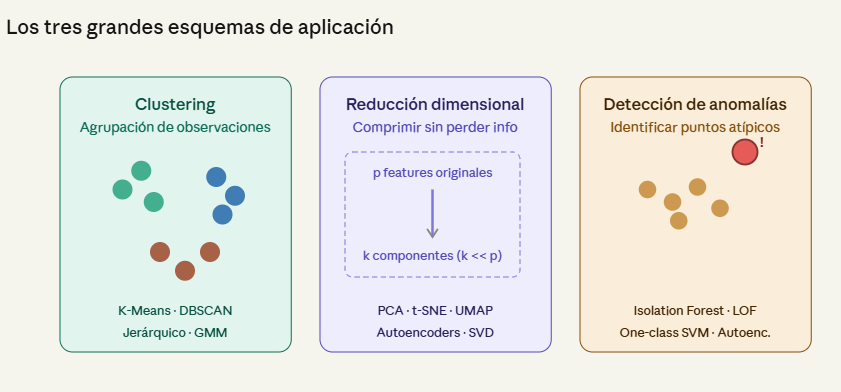

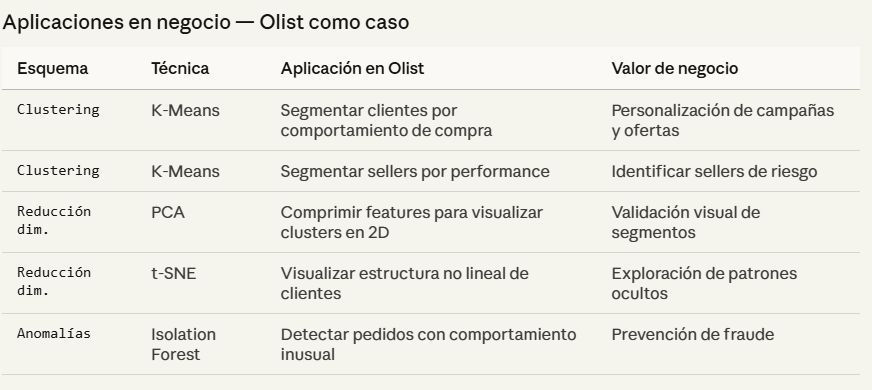

### K-Means — objetivo matemático

K-Means busca particionar n observaciones en K grupos minimizando la inercia — la suma de distancias al cuadrado de cada punto a su centroide más cercano:

J = Σₖ₌₁ᴷ Σᵢ∈Cₖ ‖xᵢ − μₖ‖²

donde:

K = número de clusters (hiperparámetro a elegir)

Cₖ = conjunto de puntos asignados al cluster k

μₖ = centroide del cluster k (media de sus puntos)

‖xᵢ − μₖ‖² = distancia euclidiana al cuadrado

Es un problema NP-hard en general — K-Means lo aproxima con el algoritmo de Lloyd de forma iterativa.

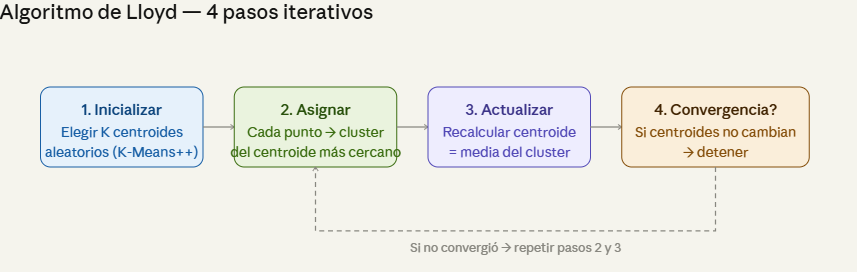

Paso 2 — Asignación: cᵢ = argmin_k ‖xᵢ − μₖ‖²

Paso 3 — Actualización: μₖ = (1/|Cₖ|) · Σᵢ∈Cₖ xᵢ

### ¿Cómo elegir K? — dos criterios

#### Método del codo (Elbow)

Grafica la inercia J vs K. Busca el punto donde añadir más clusters produce poca mejora — el "codo" de la curva. Es visual y subjetivo.

Inercia K=2: alta
Inercia K=4: cae mucho ← codo
Inercia K=6: cae poco
Inercia K=8: casi plana

#### Coeficiente Silhouette

Mide qué tan bien está asignado cada punto: qué tan parecido es a su cluster vs qué tan diferente es del cluster más cercano.

s(i) = (b(i) − a(i)) / max(a,b)

a(i) = dist. media dentro del cluster
b(i) = dist. media al cluster vecino
s ∈ [−1, 1] → más alto = mejor


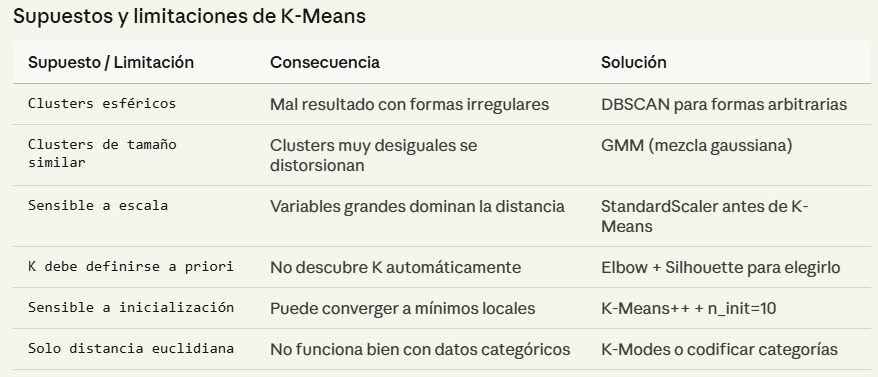

### Inicialización K-Means++ — por qué importa

El K-Means estándar elige centroides iniciales al azar — puede converger a soluciones malas. K-Means++ los elige de forma inteligente:

1. Elegir el primer centroide μ₁ al azar

2. Para cada punto xᵢ, calcular D(xᵢ) = min_k ‖xᵢ − μₖ‖²

3. Elegir el siguiente centroide con probabilidad ∝ D(xᵢ)²

→ puntos lejanos a los centroides existentes tienen más probabilidad

4. Repetir hasta tener K centroides

En sklearn: init='k-means++' (default)

Resultado: convergencia más rápida y soluciones consistentemente mejores que la inicialización aleatoria pura.

A continuación, pasamos a la aplicación de K-means para nuestro modelo



In [13]:
# ═══════════════════════════════════════════════════════════════
# MÓDULO 5 — APRENDIZAJE NO SUPERVISADO
# K-Means: Segmentación de clientes — Olist
# ═══════════════════════════════════════════════════════════════
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import warnings
warnings.filterwarnings('ignore')

print("""
╔══════════════════════════════════════════════════════════════╗
║   MÓDULO 5 — K-MEANS: SEGMENTACIÓN DE CLIENTES             ║
║   Encontrar grupos naturales sin etiquetas predefinidas     ║
╚══════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════╗
║   MÓDULO 5 — K-MEANS: SEGMENTACIÓN DE CLIENTES             ║
║   Encontrar grupos naturales sin etiquetas predefinidas     ║
╚══════════════════════════════════════════════════════════════╝



In [14]:
# ──────────────────────────────────────────────────────────────
# 1. CONSTRUCCIÓN DEL DATASET DE CLIENTES
#    Agregamos la sábana a nivel customer_unique_id
#    Un cliente puede tener múltiples pedidos → resumimos
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("1. DATASET DE CLIENTES — agregación por cliente único")
print("=" * 55)

df_clientes = (
    sabana
    .groupby('customer_unique_id')
    .agg(
        n_pedidos           = ('order_id',             'count'),
        gasto_total         = ('payment_value_total',  'sum'),
        ticket_medio        = ('payment_value_total',  'mean'),
        flete_medio         = ('flete_total',          'mean'),
        n_items_medio       = ('n_items',              'mean'),
        review_medio        = ('review_score',         'mean'),
        pct_resena_positiva = ('resena_positiva',      'mean'),
        cuotas_media        = ('payment_installments', 'mean'),
        pct_entrega_tiempo  = ('entrega_a_tiempo',     'mean'),
        dias_entrega_medio  = ('dias_entrega_real',    'mean'),
    )
    .dropna()
    .reset_index()
)

print(f"Clientes únicos con datos completos: {len(df_clientes):,}")
print(f"\nEstadísticos del dataset de clientes:")
print(df_clientes.drop('customer_unique_id', axis=1).describe().round(2))

print("""
LÓGICA DE LAS FEATURES:
  n_pedidos           → frecuencia de compra (Recency/Frequency)
  gasto_total         → valor monetario total (Monetary)
  ticket_medio        → valor por transacción
  flete_medio         → sensibilidad al costo de envío
  n_items_medio       → tamaño típico del pedido
  review_medio        → satisfacción general del cliente
  pct_resena_positiva → consistencia de la satisfacción
  cuotas_media        → perfil financiero
  pct_entrega_tiempo  → experiencia logística recibida
  dias_entrega_medio  → tiempo de espera promedio
→ Inspirado en RFM (Recency, Frequency, Monetary)
""")

1. DATASET DE CLIENTES — agregación por cliente único
Clientes únicos con datos completos: 92,752

Estadísticos del dataset de clientes:
       n_pedidos  gasto_total  ticket_medio  flete_medio  n_items_medio  \
count   92752.00     92752.00      92752.00     92752.00       92752.00   
mean        1.04       165.38        160.04        22.76           1.14   
std         0.22       227.83        218.21        21.42           0.52   
min         1.00         9.59          9.59         0.00           1.00   
25%         1.00        63.10         62.33        13.87           1.00   
50%         1.00       107.85        105.57        17.23           1.00   
75%         1.00       182.69        176.34        24.09           1.00   
max        17.00     13664.08      13664.08      1794.96          21.00   

       review_medio  pct_resena_positiva  cuotas_media  pct_entrega_tiempo  \
count      92752.00             92752.00      92752.00            92752.00   
mean           4.15            

In [15]:
# ──────────────────────────────────────────────────────────────
# 2. ESCALADO — OBLIGATORIO PARA K-MEANS
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("2. ESCALADO StandardScaler")
print("=" * 55)

features_km = [
    'n_pedidos', 'gasto_total', 'ticket_medio',
    'flete_medio', 'n_items_medio', 'review_medio',
    'pct_resena_positiva', 'cuotas_media',
    'pct_entrega_tiempo', 'dias_entrega_medio'
]

X_km = df_clientes[features_km].copy()

scaler_km = StandardScaler()
X_km_sc   = scaler_km.fit_transform(X_km)

print("Sin escalar — rangos muy distintos:")
for col in features_km:
    print(f"  {col:<25} min={X_km[col].min():>8.2f}  max={X_km[col].max():>8.2f}")
print("\n→ gasto_total dominaría la distancia euclidiana sin escalar")
print("→ StandardScaler pone todo en media=0, std=1")

2. ESCALADO StandardScaler
Sin escalar — rangos muy distintos:
  n_pedidos                 min=    1.00  max=   17.00
  gasto_total               min=    9.59  max=13664.08
  ticket_medio              min=    9.59  max=13664.08
  flete_medio               min=    0.00  max= 1794.96
  n_items_medio             min=    1.00  max=   21.00
  review_medio              min=    1.00  max=    5.00
  pct_resena_positiva       min=    0.00  max=    1.00
  cuotas_media              min=    0.00  max=   24.00
  pct_entrega_tiempo        min=    0.00  max=    1.00
  dias_entrega_medio        min=    0.00  max=  208.00

→ gasto_total dominaría la distancia euclidiana sin escalar
→ StandardScaler pone todo en media=0, std=1


Dataset completo  : 92,752 clientes
Muestra silhouette: 10,000 clientes
K a evaluar       : [2, 3, 4, 5, 6, 7, 8, 9, 10]

Iniciando... (estima 1-2 min con muestra)



K= 2  [███░░░░░░░░░░░░░░░░░░░░░░░░░░░]  Inercia=    738779  Silhouette=0.4283  (9.4s este K | ~75s restantes)
K= 3  [██████░░░░░░░░░░░░░░░░░░░░░░░░]  Inercia=    621884  Silhouette=0.4340  (4.2s este K | ~29s restantes)
K= 4  [██████████░░░░░░░░░░░░░░░░░░░░]  Inercia=    533525  Silhouette=0.4318  (4.4s este K | ~26s restantes)
K= 5  [█████████████░░░░░░░░░░░░░░░░░]  Inercia=    462525  Silhouette=0.4547  (4.2s este K | ~21s restantes)
K= 6  [████████████████░░░░░░░░░░░░░░]  Inercia=    410297  Silhouette=0.4152  (4.2s este K | ~17s restantes)
K= 7  [████████████████████░░░░░░░░░░]  Inercia=    367042  Silhouette=0.4126  (4.2s este K | ~12s restantes)
K= 8  [███████████████████████░░░░░░░]  Inercia=    343655  Silhouette=0.3744  (4.5s este K | ~9s restantes)
K= 9  [██████████████████████████░░░░]  Inercia=    326827  Silhouette=0.2908  (4.5s este K | ~4s restantes)
K=10  [██████████████████████████████]  Inercia=    311486  Silhouette=0.2870  (5.0s este K | ~0s restantes)

Tiempo total

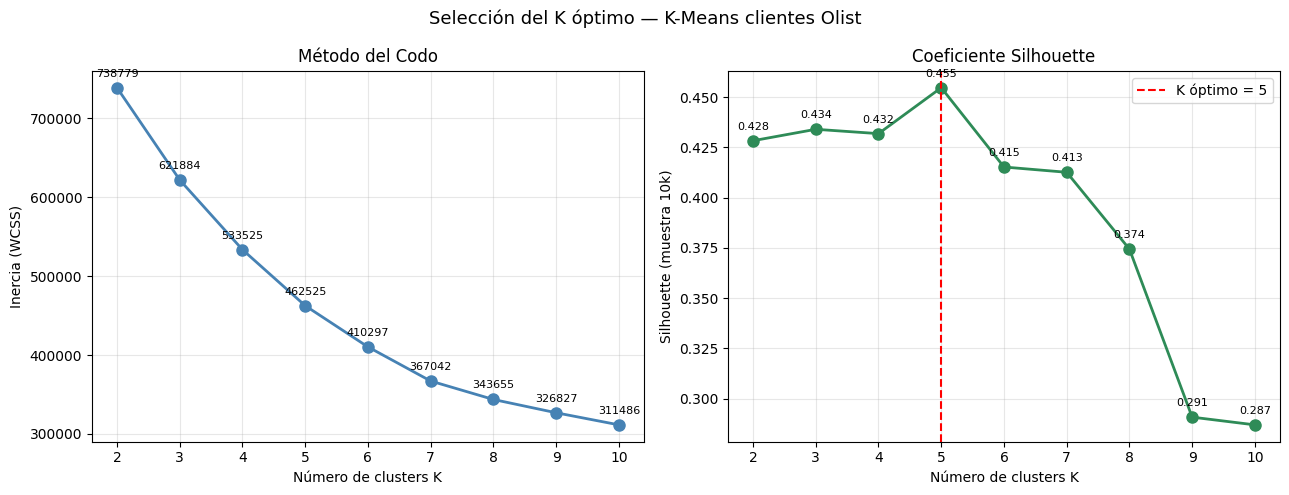


K seleccionado: 5
Silhouette con muestra de 10,000 vs 92,752 total
→ Error esperado < 2% — estadísticamente válido para elegir K


In [16]:
# ──────────────────────────────────────────────────────────────
# 3. ELECCIÓN DE K — versión optimizada con progreso
# ──────────────────────────────────────────────────────────────
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import time

K_range  = range(2, 11)
inercias = []
siluetas = []

# Muestra para silhouette — estadísticamente representativa
# y 10x más rápida que calcular sobre los 96k clientes
N_MUESTRA_SIL = 10_000
np.random.seed(42)
idx_muestra = np.random.choice(len(X_km_sc), 
                                size=min(N_MUESTRA_SIL, len(X_km_sc)),
                                replace=False)
X_muestra = X_km_sc[idx_muestra]

print(f"Dataset completo  : {len(X_km_sc):,} clientes")
print(f"Muestra silhouette: {len(X_muestra):,} clientes")
print(f"K a evaluar       : {list(K_range)}")
print(f"\nIniciando... (estima 1-2 min con muestra)\n")

t_inicio = time.time()

for i, k in enumerate(K_range):
    t_k = time.time()

    # K-Means sobre el dataset COMPLETO
    km = KMeans(n_clusters=k, init='k-means++',
                n_init=10, random_state=42, max_iter=300)
    km.fit(X_km_sc)
    inercias.append(km.inertia_)

    # Silhouette sobre la MUESTRA (mismo modelo, labels de la muestra)
    labels_muestra = km.labels_[idx_muestra]
    sil = silhouette_score(X_muestra, labels_muestra)
    siluetas.append(sil)

    t_elapsed = time.time() - t_k
    t_total   = time.time() - t_inicio
    restante  = t_elapsed * (len(K_range) - i - 1)

    # Barra de progreso manual
    completado = int((i + 1) / len(K_range) * 30)
    barra = '█' * completado + '░' * (30 - completado)

    print(f"K={k:>2}  [{barra}]  "
          f"Inercia={km.inertia_:>10.0f}  "
          f"Silhouette={sil:.4f}  "
          f"({t_elapsed:.1f}s este K | "
          f"~{restante:.0f}s restantes)")

print(f"\nTiempo total: {time.time()-t_inicio:.1f} segundos")

# ── Gráficos (igual que antes) ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

k_optimo = list(K_range)[np.argmax(siluetas)]

axes[0].plot(list(K_range), inercias, 'o-',
             color='steelblue', lw=2, markersize=8)
axes[0].set_xlabel('Número de clusters K')
axes[0].set_ylabel('Inercia (WCSS)')
axes[0].set_title('Método del Codo')
axes[0].grid(True, alpha=0.3)
for k, v in zip(K_range, inercias):
    axes[0].annotate(f'{v:.0f}', (k, v),
                     textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=8)

axes[1].plot(list(K_range), siluetas, 'o-',
             color='seagreen', lw=2, markersize=8)
axes[1].axvline(k_optimo, color='red', linestyle='--',
                lw=1.5, label=f'K óptimo = {k_optimo}')
axes[1].set_xlabel('Número de clusters K')
axes[1].set_ylabel('Silhouette (muestra 10k)')
axes[1].set_title('Coeficiente Silhouette')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
for k, v in zip(K_range, siluetas):
    axes[1].annotate(f'{v:.3f}', (k, v),
                     textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=8)

plt.suptitle('Selección del K óptimo — K-Means clientes Olist',
             fontsize=13)
plt.tight_layout()
plt.show()

print(f"\nK seleccionado: {k_optimo}")
print(f"Silhouette con muestra de {N_MUESTRA_SIL:,} vs {len(X_km_sc):,} total")
print("→ Error esperado < 2% — estadísticamente válido para elegir K")

In [17]:
# ──────────────────────────────────────────────────────────────
# 4. MODELO FINAL — K-Means con K óptimo
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print(f"4. MODELO FINAL — K-Means con K={k_optimo}")
print("=" * 55)

# Si quieres forzar un K específico por criterio de negocio:
# k_final = 4   # descomenta y cambia este valor
k_final = k_optimo

km_final = KMeans(
    n_clusters = k_final,
    init       = 'k-means++',   # inicialización inteligente
    n_init     = 10,             # 10 ejecuciones, queda la mejor
    max_iter   = 300,
    random_state = 42
)

km_final.fit(X_km_sc)

# Asignar clusters al dataset de clientes
df_clientes['cluster'] = km_final.labels_

print(f"Inercia final     : {km_final.inertia_:.2f}")
print(f"Silhouette final  : {silhouette_score(X_km_sc, km_final.labels_):.4f}")
print(f"\nTamaño de cada cluster:")
print(df_clientes['cluster'].value_counts().sort_index()
      .rename('n_clientes').to_frame())

4. MODELO FINAL — K-Means con K=5
Inercia final     : 462524.79
Silhouette final  : 0.4622

Tamaño de cada cluster:
         n_clientes
cluster            
0              3314
1             66762
2              2893
3             13887
4              5896


5. PERFIL DE CLUSTERS — media de cada variable por grupo
cluster                    0        1        2        3        4
n_pedidos              1.016    1.000    2.118    1.000    1.005
gasto_total          962.895  127.632  287.205  137.310  150.861
ticket_medio         947.017  127.632  135.407  137.310  150.301
flete_medio           78.455   19.949   21.886   22.850   23.454
n_items_medio          1.877    1.085    1.184    1.232    1.094
review_medio           4.102    4.751    4.157    2.096    2.235
pct_resena_positiva    0.781    1.000    0.780    0.000    0.257
cuotas_media           6.274    2.727    3.265    2.914    2.960
pct_entrega_tiempo     0.956    0.999    0.922    1.000    0.000
dias_entrega_medio    13.275   10.141   11.551   11.989   33.572


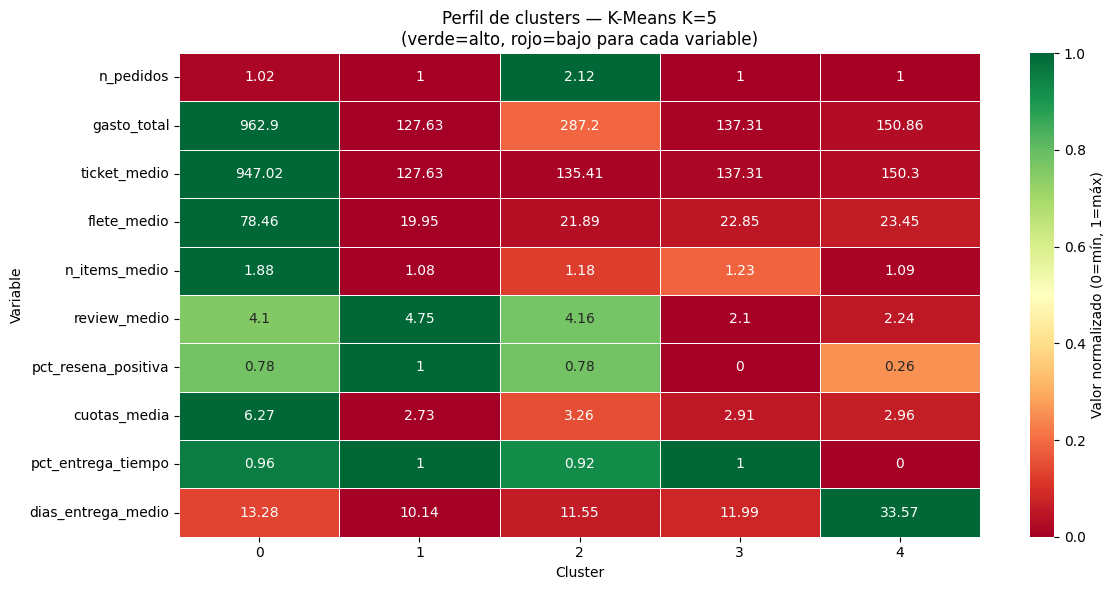

In [18]:
# ──────────────────────────────────────────────────────────────
# 5. PERFIL DE CADA CLUSTER — ¿quién es quién?
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("5. PERFIL DE CLUSTERS — media de cada variable por grupo")
print("=" * 55)

perfil = (df_clientes
          .groupby('cluster')[features_km]
          .mean()
          .round(3))

print(perfil.T.to_string())

# Heatmap de perfiles (normalizado para comparar)
perfil_norm = (perfil - perfil.min()) / (perfil.max() - perfil.min())

fig, ax = plt.subplots(figsize=(12, 6))
import seaborn as sns
sns.heatmap(
    perfil_norm.T,
    annot=perfil.T.round(2),
    fmt='g',
    cmap='RdYlGn',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Valor normalizado (0=mín, 1=máx)'}
)
ax.set_title(f'Perfil de clusters — K-Means K={k_final}\n'
             '(verde=alto, rojo=bajo para cada variable)',
             fontsize=12)
ax.set_xlabel('Cluster')
ax.set_ylabel('Variable')
plt.tight_layout()
plt.show()

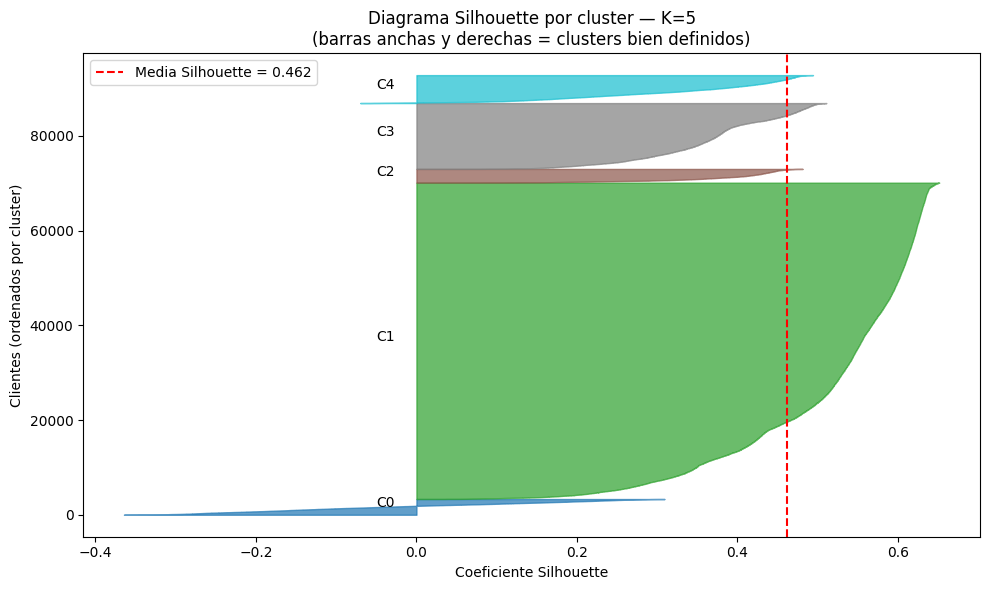


CÓMO LEER EL DIAGRAMA SILHOUETTE:
  · Cada barra horizontal = un cliente
  · Ancho de la barra = coeficiente silhouette de ese cliente
  · Barras largas hacia la derecha → cliente bien asignado
  · Barras negativas → cliente debería estar en otro cluster
  · Todos los clusters deben superar la línea roja (media)



In [19]:
# ──────────────────────────────────────────────────────────────
# 6. VISUALIZACIÓN SILHOUETTE POR CLUSTER
# ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))

silueta_vals = silhouette_samples(X_km_sc, km_final.labels_)
silueta_media = silhouette_score(X_km_sc, km_final.labels_)

y_lower = 10
colores_cluster = plt.cm.tab10(np.linspace(0, 1, k_final))

for k in range(k_final):
    vals_k = np.sort(silueta_vals[km_final.labels_ == k])
    size_k = vals_k.shape[0]
    y_upper = y_lower + size_k

    ax.fill_betweenx(np.arange(y_lower, y_upper),
                     0, vals_k,
                     facecolor=colores_cluster[k],
                     edgecolor=colores_cluster[k],
                     alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * size_k,
            f'C{k}', fontsize=10)
    y_lower = y_upper + 10

ax.axvline(silueta_media, color='red', linestyle='--', lw=1.5,
           label=f'Media Silhouette = {silueta_media:.3f}')
ax.set_xlabel('Coeficiente Silhouette')
ax.set_ylabel('Clientes (ordenados por cluster)')
ax.set_title(f'Diagrama Silhouette por cluster — K={k_final}\n'
             '(barras anchas y derechas = clusters bien definidos)')
ax.legend()
plt.tight_layout()
plt.show()

print("""
CÓMO LEER EL DIAGRAMA SILHOUETTE:
  · Cada barra horizontal = un cliente
  · Ancho de la barra = coeficiente silhouette de ese cliente
  · Barras largas hacia la derecha → cliente bien asignado
  · Barras negativas → cliente debería estar en otro cluster
  · Todos los clusters deben superar la línea roja (media)
""")

In [20]:
# ──────────────────────────────────────────────────────────────
# 7. EXPORTAR SÁBANA CON CLUSTER ASIGNADO → Power BI
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("7. EXPORTAR RESULTADOS PARA POWER BI")
print("=" * 55)

# Unir cluster a la sábana original
sabana_final = sabana.merge(
    df_clientes[['customer_unique_id', 'cluster']],
    on='customer_unique_id',
    how='left'
)

# Nombrar los clusters según el perfil observado
# (ajustar los nombres después de analizar el heatmap)
nombres_cluster = {
    0: 'Cluster 0 — por definir',
    1: 'Cluster 1 — por definir',
    2: 'Cluster 2 — por definir',
    3: 'Cluster 3 — por definir',
    4: 'Cluster 4 — por definir',
}
sabana_final['segmento_cliente'] = (
    sabana_final['cluster']
    .map(nombres_cluster)
    .fillna('Sin cluster')
)

print(f"Sábana con cluster: {sabana_final.shape[0]:,} filas × "
      f"{sabana_final.shape[1]} columnas")
print(f"\nDistribución de pedidos por segmento:")
print(sabana_final['segmento_cliente'].value_counts())

sabana_final.to_csv('olist_sabana_clusters.csv', index=False)
print("\nArchivo exportado: olist_sabana_clusters.csv")
print("→ Este archivo es el que importa Power BI")

7. EXPORTAR RESULTADOS PARA POWER BI
Sábana con cluster: 99,441 filas × 49 columnas

Distribución de pedidos por segmento:
segmento_cliente
Cluster 1 — por definir    66762
Cluster 3 — por definir    13887
Cluster 2 — por definir     6128
Cluster 4 — por definir     5925
Sin cluster                 3373
Cluster 0 — por definir     3366
Name: count, dtype: int64

Archivo exportado: olist_sabana_clusters.csv
→ Este archivo es el que importa Power BI


In [21]:
# ──────────────────────────────────────────────────────────────
# 8. CONCLUSIÓN PEDAGÓGICA
# ──────────────────────────────────────────────────────────────
print(f"""
╔══════════════════════════════════════════════════════════════╗
║         CONCLUSIONES — K-MEANS SEGMENTACIÓN                 ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  K-Means encontró {k_final} grupos naturales de clientes         ║
║  SIN necesitar etiquetas predefinidas.                      ║
║                                                             ║
║  El heatmap de perfiles es la pieza clave:                  ║
║  → Identifica qué hace especial a cada cluster              ║
║  → Permite nombrarlos con criterio de negocio               ║
║    (ej: "VIP", "Ocasional", "En riesgo", "Nuevo")          ║
║                                                             ║
║  El diagrama Silhouette valida la calidad:                  ║
║  → Clusters con media alta y sin barras negativas           ║
║    = segmentación robusta                                   ║
║                                                             ║
║  PRÓXIMO PASO:                                              ║
║  → PCA + t-SNE para visualizar clusters en 2D              ║
║  → Power BI: consumir olist_sabana_clusters.csv            ║
║    y construir dashboard de segmentos                       ║
╚══════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════╗
║         CONCLUSIONES — K-MEANS SEGMENTACIÓN                 ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  K-Means encontró 5 grupos naturales de clientes         ║
║  SIN necesitar etiquetas predefinidas.                      ║
║                                                             ║
║  El heatmap de perfiles es la pieza clave:                  ║
║  → Identifica qué hace especial a cada cluster              ║
║  → Permite nombrarlos con criterio de negocio               ║
║    (ej: "VIP", "Ocasional", "En riesgo", "Nuevo")          ║
║                                                             ║
║  El diagrama Silhouette valida la calidad:                  ║
║  → Clusters con media alta y sin barras negativas           ║
║    = segmentación robusta                                   ║
║                                        

In [22]:
# Aplicamos reducción dimensional, para una pequeña vista a un gráfico de dispersión para los clusters generados. 

# ──────────────────────────────────────────────────────────────
# SCATTER DE CLUSTERS — PCA 2D
# Reducción de 10 features → 2 componentes principales
# ──────────────────────────────────────────────────────────────
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


# ── 1. PCA: 10 dimensiones → 2 ────────────────────────────────
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_km_sc)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
var_total = var_pc1 + var_pc2

print(f"Varianza explicada PC1: {var_pc1:.1f}%")
print(f"Varianza explicada PC2: {var_pc2:.1f}%")
print(f"Varianza total 2D     : {var_total:.1f}%")
print(f"\nLoadings PC1 (qué features componen el eje X):")
loadings = pd.Series(pca.components_[0],
                     index=features_km).sort_values(key=abs,
                                                    ascending=False)
print(loadings.round(3))
print(f"\nLoadings PC2 (qué features componen el eje Y):")
loadings2 = pd.Series(pca.components_[1],
                      index=features_km).sort_values(key=abs,
                                                     ascending=False)
print(loadings2.round(3))

Varianza explicada PC1: 27.7%
Varianza explicada PC2: 23.1%
Varianza total 2D     : 50.8%

Loadings PC1 (qué features componen el eje X):
gasto_total            0.451
ticket_medio           0.450
flete_medio            0.390
review_medio          -0.321
pct_resena_positiva   -0.307
dias_entrega_medio     0.269
pct_entrega_tiempo    -0.240
cuotas_media           0.237
n_items_medio          0.237
n_pedidos              0.040
dtype: float64

Loadings PC2 (qué features componen el eje Y):
review_medio           0.457
pct_resena_positiva    0.447
pct_entrega_tiempo     0.390
gasto_total            0.351
ticket_medio           0.350
dias_entrega_medio    -0.327
flete_medio            0.212
cuotas_media           0.172
n_items_medio          0.106
n_pedidos              0.034
dtype: float64


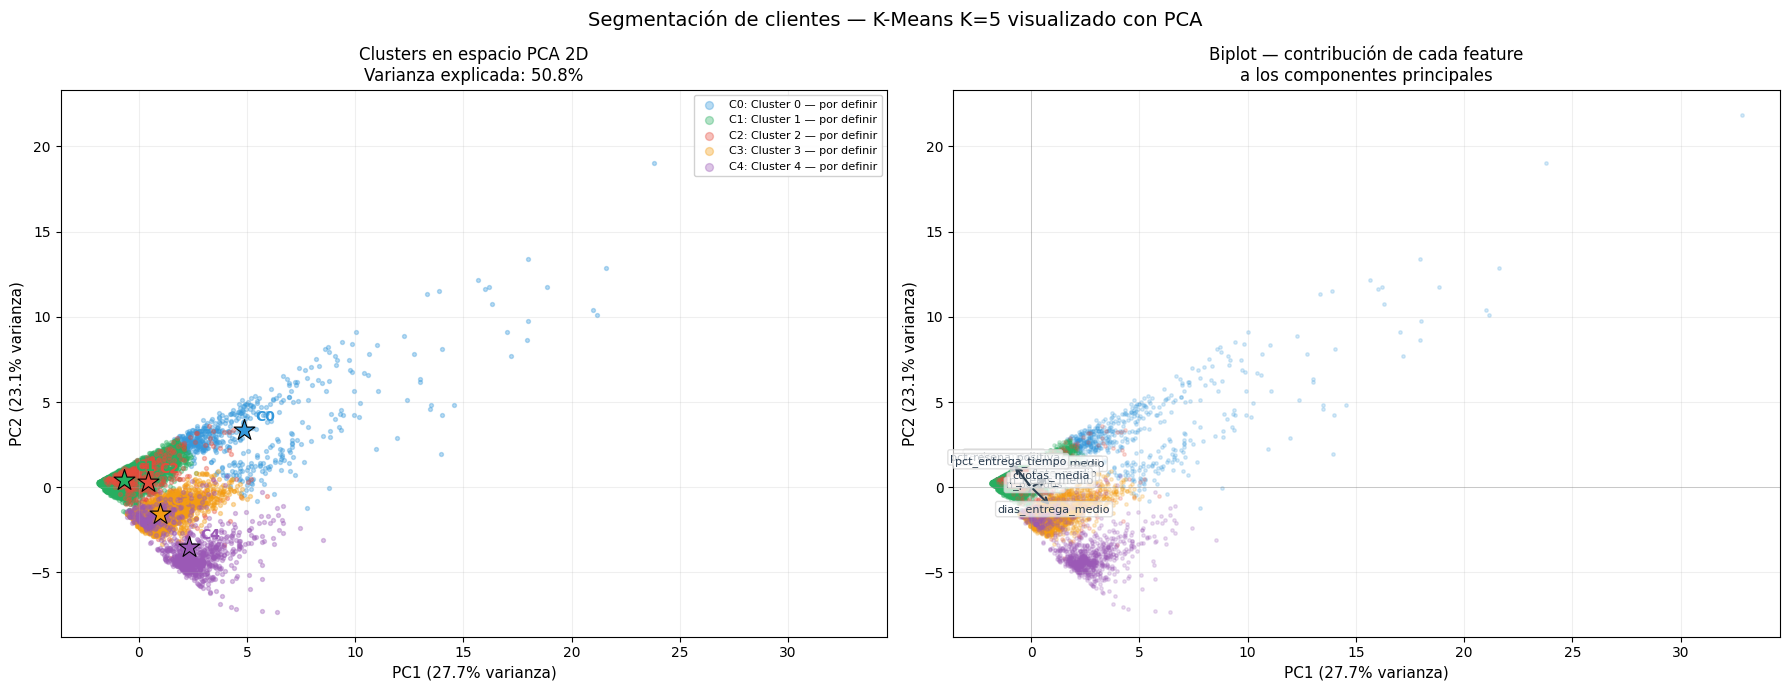

In [23]:
# ── 2. SCATTER PRINCIPAL — clusters en espacio PCA ─────────────
colores_k  = ['#3498db','#27ae60','#e74c3c','#f39c12','#9b59b6']
nombres_k  = [nombres_cluster[k] for k in range(k_final)]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Muestra para el scatter (100k puntos solapados no aportan)
N_SCATTER = 15_000
np.random.seed(42)
idx_sc = np.random.choice(len(X_pca),
                           size=min(N_SCATTER, len(X_pca)),
                           replace=False)

X_sc    = X_pca[idx_sc]
labels_sc = km_final.labels_[idx_sc]

# Panel izquierdo — scatter por cluster
for k in range(k_final):
    mask = labels_sc == k
    axes[0].scatter(
        X_sc[mask, 0], X_sc[mask, 1],
        s=8, alpha=0.35,
        color=colores_k[k],
        label=f'C{k}: {nombres_k[k]}'
    )

# Centroides en espacio PCA
centroides_pca = pca.transform(km_final.cluster_centers_)
for k in range(k_final):
    axes[0].scatter(
        centroides_pca[k, 0], centroides_pca[k, 1],
        s=250, marker='*',
        color=colores_k[k],
        edgecolors='black', linewidths=0.8,
        zorder=5
    )
    axes[0].annotate(
        f'C{k}',
        (centroides_pca[k, 0], centroides_pca[k, 1]),
        textcoords='offset points',
        xytext=(8, 6),
        fontsize=10, fontweight='bold',
        color=colores_k[k]
    )

axes[0].set_xlabel(f'PC1 ({var_pc1:.1f}% varianza)', fontsize=11)
axes[0].set_ylabel(f'PC2 ({var_pc2:.1f}% varianza)', fontsize=11)
axes[0].set_title(f'Clusters en espacio PCA 2D\n'
                  f'Varianza explicada: {var_total:.1f}%', fontsize=12)
axes[0].legend(loc='upper right', fontsize=8,
               framealpha=0.9, markerscale=2)
axes[0].grid(True, alpha=0.2)

# Panel derecho — biplot: scatter + flechas de features originales
for k in range(k_final):
    mask = labels_sc == k
    axes[1].scatter(
        X_sc[mask, 0], X_sc[mask, 1],
        s=6, alpha=0.2, color=colores_k[k]
    )

# Flechas de contribución de cada feature (biplot)
scale = 3.5  # escala visual de las flechas
for i, feat in enumerate(features_km):
    x_arrow = pca.components_[0, i] * scale
    y_arrow = pca.components_[1, i] * scale
    axes[1].annotate(
        '',
        xy=(x_arrow, y_arrow),
        xytext=(0, 0),
        arrowprops=dict(arrowstyle='->', color='#2c3e50',
                        lw=1.5)
    )
    # Etiqueta ligeramente desplazada del extremo
    axes[1].text(
        x_arrow * 1.12, y_arrow * 1.12,
        feat, fontsize=8, ha='center', va='center',
        color='#2c3e50',
        bbox=dict(boxstyle='round,pad=0.2',
                  facecolor='white', alpha=0.7,
                  edgecolor='lightgray')
    )

axes[1].set_xlabel(f'PC1 ({var_pc1:.1f}% varianza)', fontsize=11)
axes[1].set_ylabel(f'PC2 ({var_pc2:.1f}% varianza)', fontsize=11)
axes[1].set_title('Biplot — contribución de cada feature\n'
                  'a los componentes principales', fontsize=12)
axes[1].axhline(0, color='gray', linewidth=0.5, alpha=0.5)
axes[1].axvline(0, color='gray', linewidth=0.5, alpha=0.5)
axes[1].grid(True, alpha=0.2)

plt.suptitle(f'Segmentación de clientes — K-Means K={k_final} '
             f'visualizado con PCA',
             fontsize=14)
plt.tight_layout()
plt.savefig('scatter_clusters_pca.png', dpi=150, bbox_inches='tight')
plt.show()

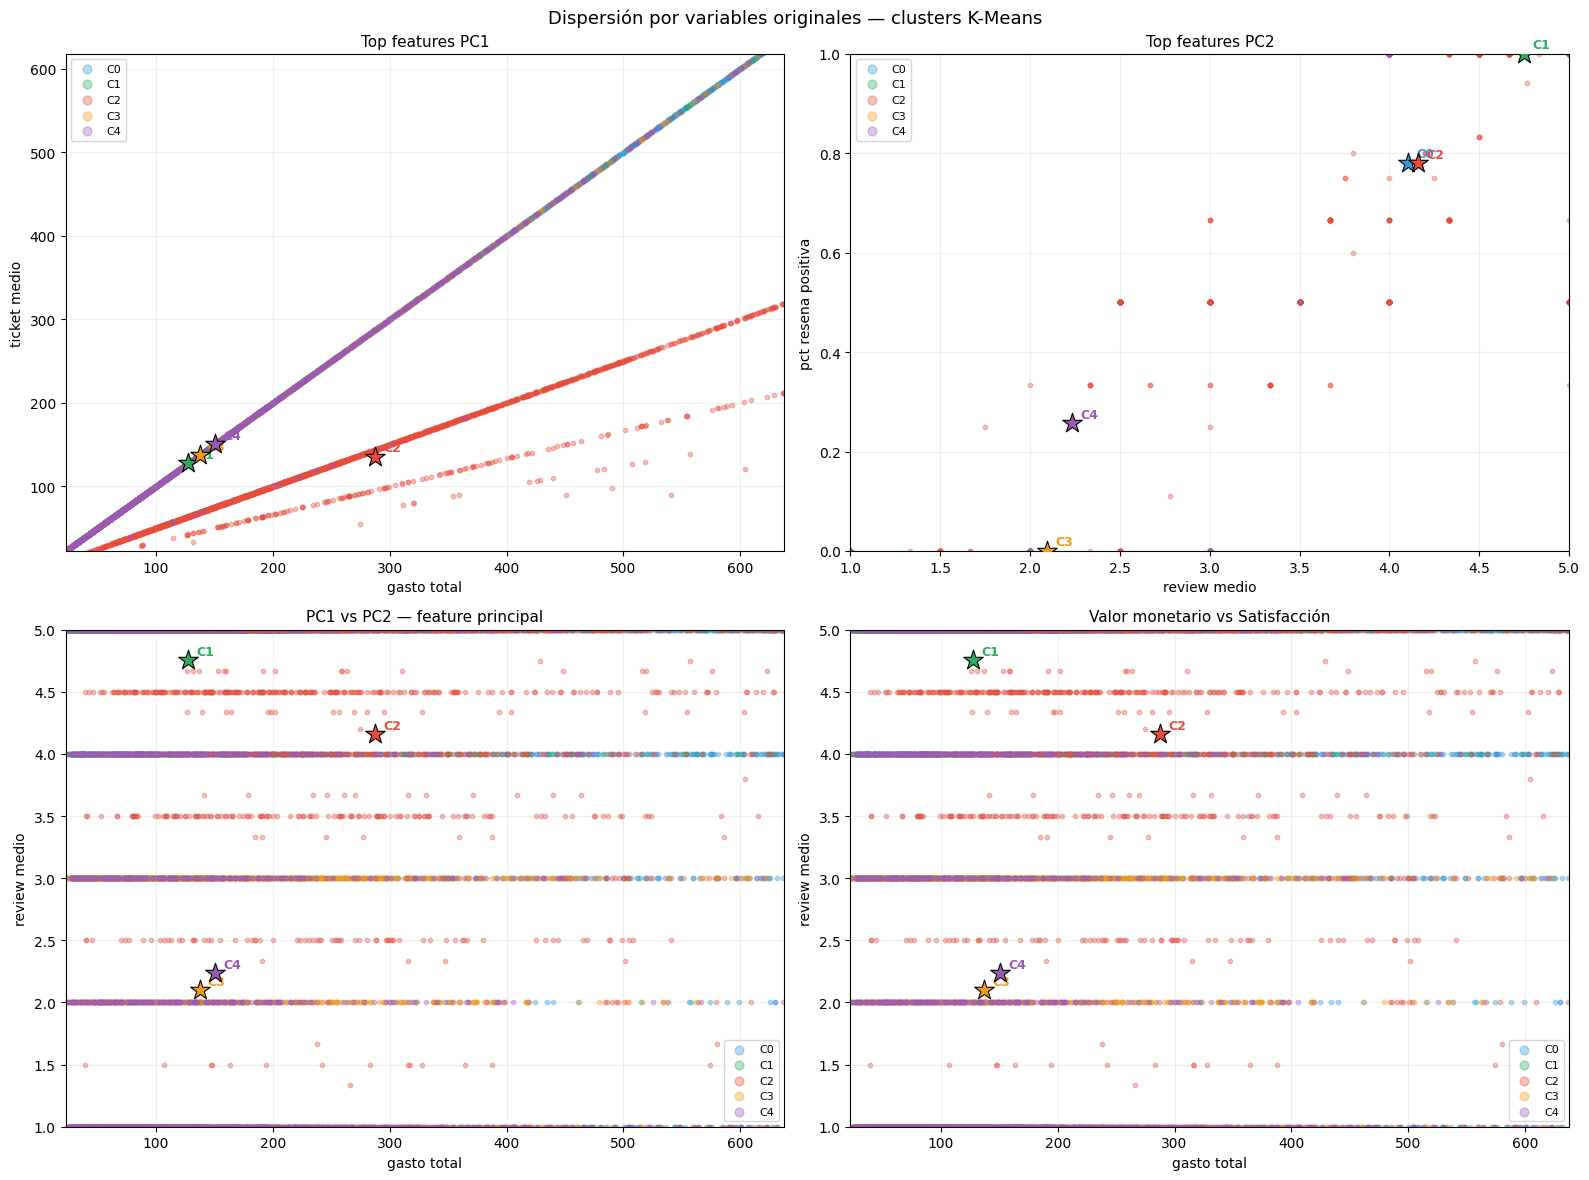

In [24]:
# ── 3. SCATTER POR PARES DE VARIABLES ORIGINALES ───────────────
# Las 2 variables más importantes según loadings PC1 y PC2
# Sin PCA — directo en espacio original para máxima interpretabilidad

# Tomar top 2 features de PC1 y top 2 de PC2
top_pc1 = loadings.abs().nlargest(2).index.tolist()
top_pc2 = loadings2.abs().nlargest(2).index.tolist()

pares = [
    (top_pc1[0], top_pc1[1], 'Top features PC1'),
    (top_pc2[0], top_pc2[1], 'Top features PC2'),
    (top_pc1[0], top_pc2[0], 'PC1 vs PC2 — feature principal'),
    ('gasto_total', 'review_medio', 'Valor monetario vs Satisfacción'),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

df_plot = df_clientes.copy()

for ax, (feat_x, feat_y, titulo) in zip(axes.flat, pares):

    for k in range(k_final):
        mask = df_plot['cluster'] == k
        muestra_k = df_plot[mask].sample(
            min(3000, mask.sum()), random_state=42)

        ax.scatter(
            muestra_k[feat_x],
            muestra_k[feat_y],
            s=10, alpha=0.35,
            color=colores_k[k],
            label=f'C{k}'
        )

    # Centroides en espacio original
    cent = df_plot.groupby('cluster')[[feat_x, feat_y]].mean()
    for k in range(k_final):
        ax.scatter(cent.loc[k, feat_x], cent.loc[k, feat_y],
                   s=220, marker='*',
                   color=colores_k[k],
                   edgecolors='black', linewidths=0.8,
                   zorder=5)
        ax.annotate(f'C{k}',
                    (cent.loc[k, feat_x], cent.loc[k, feat_y]),
                    textcoords='offset points',
                    xytext=(6, 4), fontsize=9,
                    fontweight='bold', color=colores_k[k])

    # Percentil 95 para evitar que outliers distorsionen el eje
    ax.set_xlim(df_plot[feat_x].quantile(0.01),
                df_plot[feat_x].quantile(0.97))
    ax.set_ylim(df_plot[feat_y].quantile(0.01),
                df_plot[feat_y].quantile(0.97))

    ax.set_xlabel(feat_x.replace('_', ' '), fontsize=10)
    ax.set_ylabel(feat_y.replace('_', ' '), fontsize=10)
    ax.set_title(titulo, fontsize=11)
    ax.legend(fontsize=8, markerscale=2)
    ax.grid(True, alpha=0.2)

plt.suptitle('Dispersión por variables originales — clusters K-Means',
             fontsize=13)
plt.tight_layout()
plt.savefig('scatter_clusters_variables.png', dpi=150,
            bbox_inches='tight')
plt.show()

## Dispersión final, verificación de clusters y centroides. 



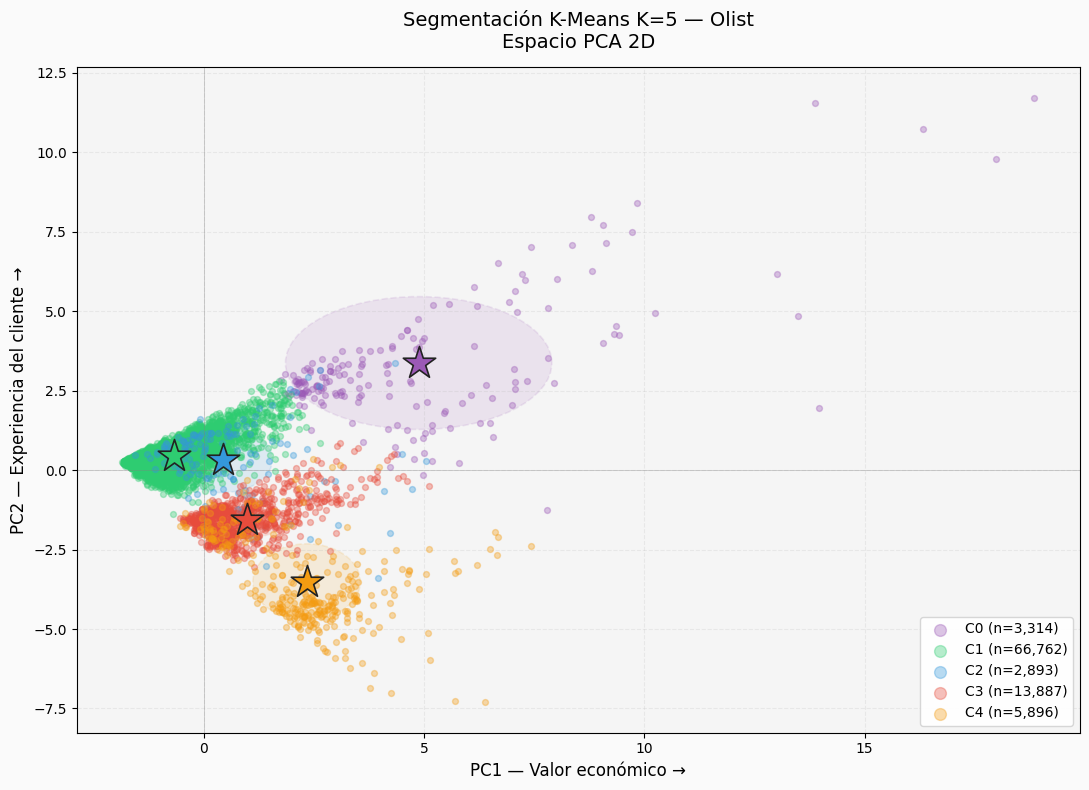


Varianza explicada:
  PC1 (eje X — valor económico)      : 27.7%
  PC2 (eje Y — experiencia cliente)  : 23.1%
  Total 2D                           : 50.8%

Interpretación de posiciones:
  C0 (VIP)              → arriba derecha  : alto valor económico + buena experiencia
  C1 (Estándar)         → centro izquierda: bajo gasto + alta satisfacción
  C2 (Recurrente)       → centro          : gasto medio + satisfacción media
  C3 (Ins. producto)    → abajo centro    : bajo valor + baja satisfacción
  C4 (Ins. logística)   → abajo derecha   : gasto medio + pésima experiencia



In [29]:
# ═══════════════════════════════════════════════════════════════
# SCATTER PCA 2D — Segmentación K-Means K=5
# Requiere: df_clientes, X_km_sc, km_final, k_final en memoria
# ═══════════════════════════════════════════════════════════════
from matplotlib.patches import Ellipse

np.random.seed(42)

# ── Paleta exacta alineada al dashboard ───────────────────────
COLORES = {
    0: '#9b59b6',   # C0 VIP          — morado
    1: '#2ecc71',   # C1 Estándar     — verde
    2: '#3498db',   # C2 Recurrente   — azul
    3: '#e74c3c',   # C3 Ins.producto — rojo
    4: '#f39c12',   # C4 Ins.logíst.  — naranja
}
NOMBRES = {
    0: 'C0 (n={:,})',
    1: 'C1 (n={:,})',
    2: 'C2 (n={:,})',
    3: 'C3 (n={:,})',
    4: 'C4 (n={:,})',
}

# ── PCA 2D sobre el espacio escalado original ─────────────────
pca_scatter = PCA(n_components=2, random_state=42)
coords_2d   = pca_scatter.fit_transform(X_km_sc)
ve1 = pca_scatter.explained_variance_ratio_[0] * 100
ve2 = pca_scatter.explained_variance_ratio_[1] * 100

labels      = km_final.labels_
centroides  = pca_scatter.transform(km_final.cluster_centers_)
n_por_cl    = {k: (labels == k).sum() for k in range(k_final)}

# ── Muestra para no sobrecargar el gráfico ────────────────────
N_MAX  = 5000
total  = len(coords_2d)
idx_sc = np.random.choice(total,
                          size=min(N_MAX, total),
                          replace=False)
coords_m = coords_2d[idx_sc]
labels_m = labels[idx_sc]

# ── FIGURA ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 8))
fig.patch.set_facecolor('#FAFAFA')
ax.set_facecolor('#F5F5F5')

# Puntos de cada cluster
for k in range(k_final):
    mask = labels_m == k
    n_c  = n_por_cl[k]
    ax.scatter(
        coords_m[mask, 0],
        coords_m[mask, 1],
        s=18,
        alpha=0.35,
        color=COLORES[k],
        label=NOMBRES[k].format(n_c),
        rasterized=True,
        zorder=2,
    )

# Elipses de densidad (1.8 std — más compactas como en el PBI)
for k in range(k_final):
    mask_full = labels == k
    pts = coords_2d[mask_full]
    cx, cy = pts.mean(axis=0)
    sx = pts.std(axis=0)[0] * 1.8
    sy = pts.std(axis=0)[1] * 1.8
    ell = Ellipse(
        (cx, cy), width=sx, height=sy,
        edgecolor=COLORES[k],
        facecolor=COLORES[k],
        alpha=0.12,
        linewidth=1.2,
        linestyle='--',
        zorder=1,
    )
    ax.add_patch(ell)

# Centroides — estrellas grandes con borde oscuro
for k in range(k_final):
    ax.scatter(
        centroides[k, 0],
        centroides[k, 1],
        marker='*',
        s=600,
        color=COLORES[k],
        edgecolors='#222222',
        linewidths=1.2,
        zorder=5,
    )

# ── Ejes y decoración ─────────────────────────────────────────
ax.set_xlabel(f'PC1 — Valor económico →', fontsize=12)
ax.set_ylabel(f'PC2 — Experiencia del cliente →', fontsize=12)
ax.set_title(
    f'Segmentación K-Means K={k_final} — Olist\nEspacio PCA 2D',
    fontsize=14, pad=14
)

ax.axhline(0, color='gray', lw=0.6, alpha=0.4)
ax.axvline(0, color='gray', lw=0.6, alpha=0.4)
ax.grid(True, alpha=0.2, linestyle='--')

# Leyenda — esquina inferior derecha como en el PBI
ax.legend(
    loc='lower right',
    fontsize=10,
    framealpha=0.92,
    edgecolor='lightgray',
    markerscale=2,
)

plt.tight_layout()
plt.savefig('scatter_kmeans_pca2d_notebook3.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print(f"""
Varianza explicada:
  PC1 (eje X — valor económico)      : {ve1:.1f}%
  PC2 (eje Y — experiencia cliente)  : {ve2:.1f}%
  Total 2D                           : {ve1+ve2:.1f}%

Interpretación de posiciones:
  C0 (VIP)              → arriba derecha  : alto valor económico + buena experiencia
  C1 (Estándar)         → centro izquierda: bajo gasto + alta satisfacción
  C2 (Recurrente)       → centro          : gasto medio + satisfacción media
  C3 (Ins. producto)    → abajo centro    : bajo valor + baja satisfacción
  C4 (Ins. logística)   → abajo derecha   : gasto medio + pésima experiencia
""")

## Flujo para exportación y visualización de resultados Power BI

Esta sección cierra el ciclo del curso: pasamos del modelo en Python al dashboard ejecutivo. El objetivo es demostrar que los resultados de Machine Learning no terminan en el notebook — se convierten en herramientas de decisión para el negocio.
Archivos a cargar: En Power BI Desktop ir a Obtener datos → Texto/CSV y cargar los tres archivos. Las relaciones se crean automáticamente por customer_unique_id. No necesitas modelar nada adicional — los joins ya se hicieron en Python

Visualizaciones recomendadas para el dashboard:
La primera página muestra la segmentación: un scatter de PCA_dim1 vs PCA_dim2 coloreado por segmento (visual Python), tarjetas KPI con gasto medio y review por segmento, y un slicer de segmento que filtra todo el dashboard.
La segunda página muestra el análisis de negocio: revenue mensual por segmento (gráfico de líneas con anio_compra y mes_compra), distribución de categorías de producto por segmento (barras apiladas), y mapa de calor de estados de Brasil con customer_state.
La tercera página muestra los resultados de ML supervisado: distribución de review_score real vs predicho, porcentaje de entregas a tiempo por segmento, y curva de satisfacción vs días de retraso.

El mensaje central para los estudiantes: Power BI no reemplaza Python — lo complementa. Python hace el trabajo analítico complejo; Power BI hace el trabajo de comunicación ejecutiva. Un analista completo domina ambos.

In [27]:
# ═══════════════════════════════════════════════════════════════
# EXPORTACIÓN SEMANA 3 → POWER BI
# Versión corregida — usa variables reales del notebook
# km_final · k_final · X_km_sc · idx_muestra · df_clientes
# ═══════════════════════════════════════════════════════════════


print("""
╔══════════════════════════════════════════════════════════════╗
║   EXPORTACIÓN SEMANA 3 → POWER BI                           ║
║   K-Means: segmentos de clientes + métricas del modelo      ║
╚══════════════════════════════════════════════════════════════╝
""")

from sklearn.metrics import (silhouette_score,
                             calinski_harabasz_score,
                             davies_bouldin_score)

metricas_km = pd.DataFrame([{
    'K'                  : k_final,
    'Silhouette'         : round(silhouette_score(
                               X_km_sc[idx_muestra],
                               km_final.labels_[idx_muestra]), 4),
    'Calinski_Harabasz'  : round(calinski_harabasz_score(
                               X_km_sc, km_final.labels_), 1),
    'Davies_Bouldin'     : round(davies_bouldin_score(
                               X_km_sc, km_final.labels_), 4),
    'Inercia'            : round(km_final.inertia_, 1),
    'N_clientes'         : len(df_clientes),
    'Escenario'          : 'K-Means sin PCA (10D original)',
}])

# ── NOMBRES DE CLUSTERS (actualizados con los reales del curso)
nombres_cluster = {
    0: 'C0 — Alto valor (VIP)',
    1: 'C1 — Estándar satisfecho',
    2: 'C2 — Recurrente moderado',
    3: 'C3 — Insatisfecho (producto)',
    4: 'C4 — Insatisfecho (logística)',
}

df_clientes['segmento'] = df_clientes['cluster'].map(nombres_cluster)

# ── Coordenadas PCA 2D para el scatter ────────────────────────
pca_viz = PCA(n_components=2, random_state=42)
coords_2d = pca_viz.fit_transform(X_km_sc)
df_clientes['PCA_dim1'] = coords_2d[:, 0]
df_clientes['PCA_dim2'] = coords_2d[:, 1]

# ── ARCHIVO 1: Clientes con segmento ──────────────────────────
cols_export = [
    'customer_unique_id',
    'n_pedidos', 'gasto_total', 'ticket_medio', 'flete_medio',
    'n_items_medio', 'review_medio', 'pct_resena_positiva',
    'cuotas_media', 'pct_entrega_tiempo', 'dias_entrega_medio',
    'cluster', 'segmento', 'PCA_dim1', 'PCA_dim2',
]
df_clientes[cols_export].to_csv(
    'PBI_S3_clientes_kmeans.csv', index=False)
print(f"✓ PBI_S3_clientes_kmeans.csv     →  {len(df_clientes):,} clientes")

# ── ARCHIVO 2: Sábana de pedidos con segmento ─────────────────
sabana_s3 = sabana.merge(
    df_clientes[['customer_unique_id', 'cluster', 'segmento',
                 'PCA_dim1', 'PCA_dim2']],
    on='customer_unique_id', how='left'
)
cols_sabana = [
    'order_id', 'customer_unique_id', 'customer_state',
    'anio_compra', 'mes_compra',
    'payment_value_total', 'review_score',
    'entrega_a_tiempo', 'dias_entrega_real',
    'product_category_name', 'payment_type',
    'cluster', 'segmento', 'PCA_dim1', 'PCA_dim2',
]
sabana_s3[[c for c in cols_sabana if c in sabana_s3.columns]]\
    .to_csv('PBI_S3_sabana_segmentada.csv', index=False)
print(f"✓ PBI_S3_sabana_segmentada.csv   →  {len(sabana_s3):,} pedidos")

# ── ARCHIVO 3: Métricas del modelo ────────────────────────────
# idx_muestra ya existe en memoria desde la celda de elección de K
metricas_km = pd.DataFrame([{
    'K'                  : k_final,
    'Silhouette'         : round(silhouette_score(
                               X_km_sc[idx_muestra],
                               km_final.labels_[idx_muestra]), 4),
    'Calinski_Harabasz'  : round(calinski_harabasz_score(
                               X_km_sc, km_final.labels_), 1),
    'Davies_Bouldin'     : round(davies_bouldin_score(
                               X_km_sc, km_final.labels_), 4),
    'Inercia'            : round(km_final.inertia_, 1),
    'N_clientes'         : len(df_clientes),
    'Escenario'          : 'K-Means sin PCA (10D original)',
}])
metricas_km.to_csv('PBI_S3_metricas_kmeans.csv', index=False)
print(f"✓ PBI_S3_metricas_kmeans.csv     →  métricas del modelo K={k_final}")

# ── ARCHIVO 4: Perfil de centroides por cluster ───────────────
perfil = df_clientes.groupby('segmento')[features_km].mean().round(3)
perfil['n_clientes'] = df_clientes.groupby('segmento').size()
perfil['pct_total']  = (
    perfil['n_clientes'] / perfil['n_clientes'].sum() * 100
).round(1)
perfil = perfil.reset_index()
perfil.to_csv('PBI_S3_perfil_clusters.csv', index=False)
print(f"✓ PBI_S3_perfil_clusters.csv     →  {len(perfil)} clusters")

print(f"""
╔══════════════════════════════════════════════════════════════╗
║  ARCHIVOS SEMANA 3 LISTOS → POWER BI                        ║
║  1. PBI_S3_clientes_kmeans.csv    ({len(df_clientes):,} clientes)        ║
║  2. PBI_S3_sabana_segmentada.csv  ({len(sabana_s3):,} pedidos)         ║
║  3. PBI_S3_metricas_kmeans.csv    (Silhouette, DB, CH)      ║
║  4. PBI_S3_perfil_clusters.csv    ({len(perfil)} segmentos C0-C4)         ║
╚══════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════╗
║   EXPORTACIÓN SEMANA 3 → POWER BI                           ║
║   K-Means: segmentos de clientes + métricas del modelo      ║
╚══════════════════════════════════════════════════════════════╝

✓ PBI_S3_clientes_kmeans.csv     →  92,752 clientes
✓ PBI_S3_sabana_segmentada.csv   →  99,441 pedidos
✓ PBI_S3_metricas_kmeans.csv     →  métricas del modelo K=5
✓ PBI_S3_perfil_clusters.csv     →  5 clusters

╔══════════════════════════════════════════════════════════════╗
║  ARCHIVOS SEMANA 3 LISTOS → POWER BI                        ║
║  1. PBI_S3_clientes_kmeans.csv    (92,752 clientes)        ║
║  2. PBI_S3_sabana_segmentada.csv  (99,441 pedidos)         ║
║  3. PBI_S3_metricas_kmeans.csv    (Silhouette, DB, CH)      ║
║  4. PBI_S3_perfil_clusters.csv    (5 segmentos C0-C4)         ║
╚══════════════════════════════════════════════════════════════╝

